# Drift scenarios: input PSI (F22)

Four seeded samples of real rides: GBG500 training rides for normal and riskier mix, and the same SRV3490 development rides from city 1 with and without rotation conversion. The reference is derived from the GBG500 training population, so normal is not an independent false-alarm estimate. City 1 is unseen by model 1, not necessarily by model 2.

Generate reports first: `make scenario NAME=<name>` followed by `make drift DRIFT_CURRENT=reports/scenarios/<name>.parquet DRIFT_OUT=reports/drift/<name>` for each of `normal`, `riskier_mix`, `unseen_city`, `unit_bug`. Exit 3 means drift was detected and the report was written. These are offline input comparisons, not live dashboard validation.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from ride_classifier.config import ROOT, load_params
from ride_classifier.features.window_stats import FEATURES
from ride_classifier.viz.theme import apply_theme, save_fig

names = ['normal', 'riskier_mix', 'unseen_city', 'unit_bug']
paths = {name: ROOT / 'reports' / 'drift' / name / 'drift_report.json' for name in names}
missing = [str(path) for path in paths.values() if not path.exists()]
if missing:
    raise FileNotFoundError('Generate the scenario reports first: ' + ', '.join(missing))
reports = {name: json.loads(path.read_text(encoding='utf-8')) for name, path in paths.items()}
for name, report in reports.items():
    print(f"{name}: {report['n_windows']} windows, {report['status']}")

normal: 1847 windows, ok
riskier_mix: 1951 windows, ok
unseen_city: 2832 windows, retrain_recommended
unit_bug: 2832 windows, retrain_recommended


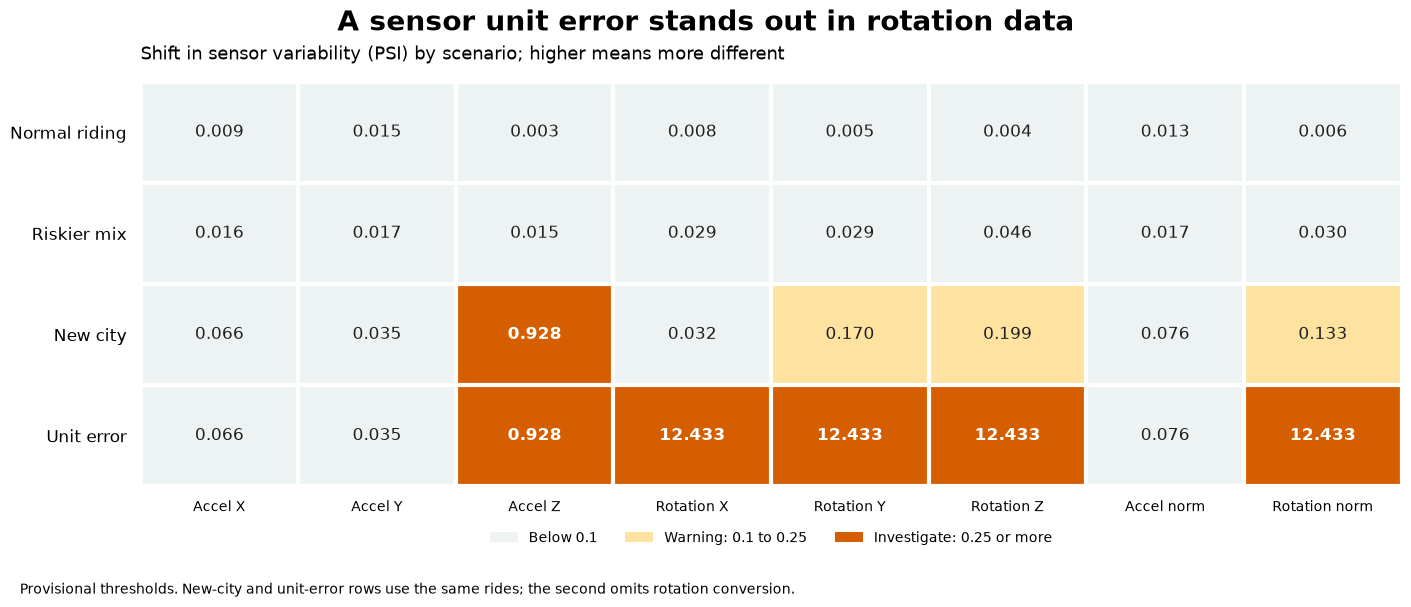

In [2]:
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

apply_theme()
values = np.array([[reports[name]["features"][feature]["psi"] for feature in FEATURES] for name in names])
thresholds = load_params()["drift"]
alert, investigate = thresholds["psi_alert"], thresholds["psi_retrain"]
fig, ax = plt.subplots(figsize=(14, 5.5), constrained_layout=True)
fig.suptitle("A sensor unit error stands out in rotation data", fontsize=20, fontweight="bold")
ax.set_title("Shift in sensor variability (PSI) by scenario; higher means more different", loc="left", fontsize=13, pad=16)
cmap = ListedColormap(["#edf2f3", "#fde2a0", "#d55e00"])
norm = BoundaryNorm([0, alert, investigate, np.inf], cmap.N)
ax.imshow(values, cmap=cmap, norm=norm, aspect="auto")
ax.set_xticks(range(len(FEATURES)), ["Accel X", "Accel Y", "Accel Z", "Rotation X", "Rotation Y", "Rotation Z", "Accel norm", "Rotation norm"], rotation=0, fontsize=10)
ax.set_yticks(range(4), ["Normal riding", "Riskier mix", "New city", "Unit error"], fontsize=12)
ax.tick_params(length=0, pad=10)
for row in range(len(names)):
    for col in range(len(FEATURES)):
        value = values[row, col]
        ax.text(col, row, f"{value:.3f}", ha="center", va="center", fontsize=12,
                color="white" if value >= investigate else "#202020", fontweight="bold" if value >= investigate else "normal")
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_xticks(np.arange(-0.5, len(FEATURES), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(names), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=3)
ax.tick_params(which="minor", bottom=False, left=False)
ax.legend(handles=[Patch(facecolor="#edf2f3", label=f"Below {alert:g}"),
                   Patch(facecolor="#fde2a0", label=f"Warning: {alert:g} to {investigate:g}"),
                   Patch(facecolor="#d55e00", label=f"Investigate: {investigate:g} or more")],
          loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False, fontsize=10)
fig.text(0.01, -0.07, "Provisional thresholds. New-city and unit-error rows use the same rides; the second omits rotation conversion.", fontsize=10)
save_fig(fig, "F22", "drift_scenario_psi")
plt.show()

Each cell is the population stability index (PSI): a larger value means a greater shift from the training reference. The thresholds are provisional. Normal and riskier GBG500 samples remain below them in this run. For the same city rides, the unit bug produces a much larger shift in rotation features; the required response is to fix the sender. The city sample also shifts acceleration Z. The training-derived normal sample does not establish an independent false-alarm rate. Outcome performance (F44) requires labelled API replay and is not yet measured.